In [1]:
import matplotlib.pyplot as plt
from astropy.io import fits
import numpy as np

In [2]:
header_list = []
data_list = []


for i in range(1, 6):
    path = "M13_000" + str(i) + ".fits"
    with fits.open(path) as hdul:
        header_list.append(hdul[0].header)
        data_list.append(hdul[0].data)

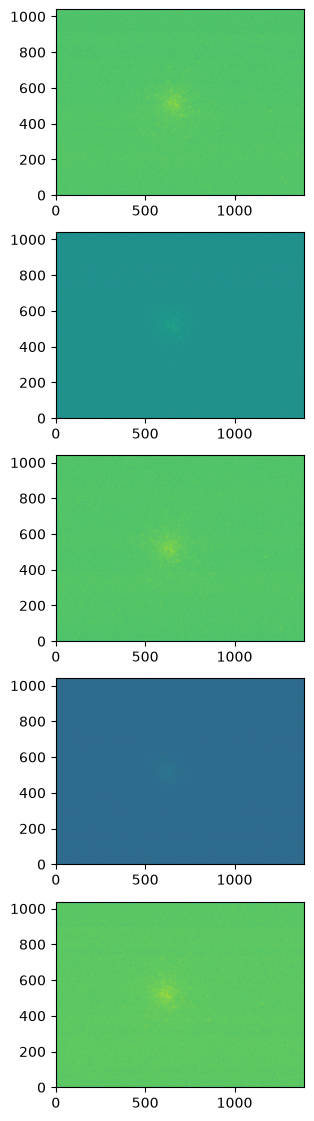

In [3]:
figs, axes = plt.subplots(5, 1, figsize = (4, 14))
for i in range(0, 5):
    axes[i].imshow(data_list[i], cmap = 'viridis', origin = 'lower')
    
plt.show()

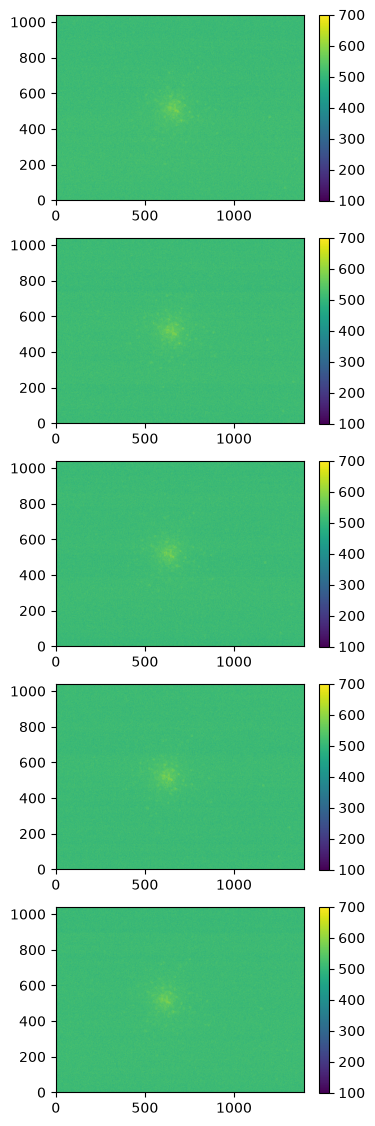

In [4]:
figs, axes = plt.subplots(5, 1, figsize = (4, 14))
for i in range(0, 5):
    im = axes[i].imshow(data_list[i], cmap='viridis', origin = 'lower', vmin = 100, vmax = 700)
    figs.colorbar(im)
plt.show()

The images are way more uniform in their color distribution.

512.0
510.4706668600796
511.0
509.7460150033157
510.0
508.0498729000884
509.0
507.90583554376656
510.0
508.7919920148099


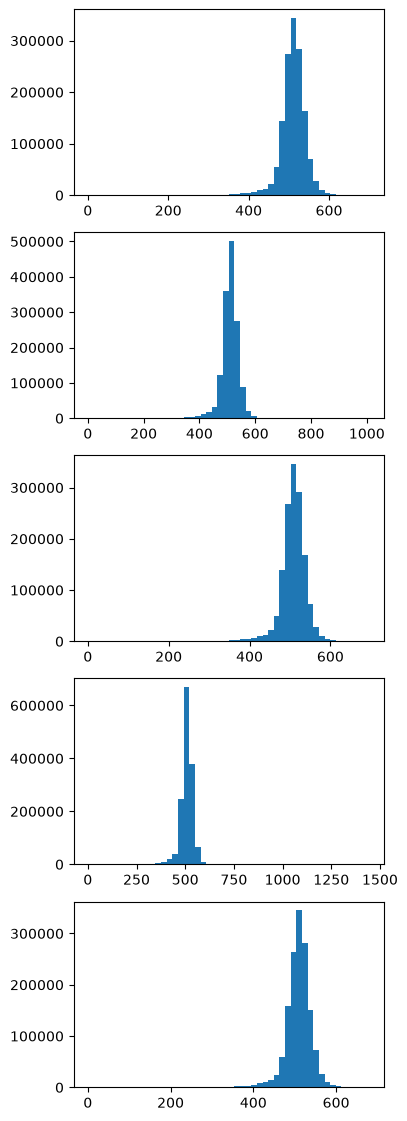

In [5]:
figs, axes = plt.subplots(5, 1, figsize = (4, 14))
for i in range(0, 5):
    axes[i].hist(data_list[i].ravel(), bins = 50)
    print(np.median(data_list[i].ravel()))
    print(np.mean(data_list[i].ravel()))

plt.show()



The values on the x axis is the value associated with an individual pixel for the purpose of making the image a 3d file. The values on the y axis is the number of pixels with taht associated value.

bins=50 means we have 50 individual possible x axis values we can categorize the pixels into. The data is mostly centered around 500ish.

The data is spread in a pretty normal distribution around 400ish to 600ish.

The medians are as follows:

#1: 512
#2: 511
#3: 510
#4: 509
#5: 510

Means are as follows:

#1: 510.4706668600796
#2: 509.7460150033157
#3: 508.0498729000884
#4: 507.90583554376656
#5: 508.7919920148099

In [6]:
combined_image = np.median(data_list, axis=0)

In [ ]:
plt.hist(combined_image, bins=50)
plt.show()

In [ ]:
plt.figure(figsize=(10,10))
plt.imshow(combined_image, cmap='viridis', vmin = 450, vmax = 550)
plt.colorbar()
plt.show()

The image is a lot more clear, with a definite spot in the center (I guess a star or something?)

In [ ]:
fits.writeto("combined.fits", combined_image, overwrite=True)

In [ ]:
figs, axes = plt.subplots(5, 1, figsize = (4, 14))
for i in range(0, 5):
    im = axes[i].imshow(data_list[i], cmap='viridis', origin = 'lower', vmin = 450, vmax = 550)
    figs.colorbar(im)
plt.show()